In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from DDRLBase import DDRLBase

from Methods import quantile, expectile, weights

In [ ]:
# imports for this notebook
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pyCRLD.Utils import FlowPlot as fp

# test environment
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma

# regular Actor-Critic agent
from DDRLActorCritic import DDRLActorCritic

In [ ]:
# Define environment
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)
env

RiskRewardDilemma_0.1_0.2_0.5_1_0

In [ ]:
Xsafe = np.array([[[0.999,0.001],[1,0]]])
Xrisk = np.array([[[0.001,0.999],[1,0]]])

In [ ]:
aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                      learning_rates=0.1, discount_factors=0.9, 
                      Rmin=0, Rmax=1,
                      method="weights", wU=5, use_prefactor=True)

In [ ]:
aei.Visa(Xrisk)[0, 0, :], aei.Visa(Xsafe)[0, 0, :]

(Array([0.50908506, 0.51578605], dtype=float32),
 Array([0.5574743, 0.563989 ], dtype=float32))

In [ ]:
discountfactors = np.linspace(0.01, 0.99, 41)
weights = np.array([0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 
                    0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85,
                    0.9, 0.95, 1., 1.5, 2., 2.5, 3., 3.5, 4., 4.5,
                    5., 5.5, 6., 6.5, 7., 7.5, 8., 8.5, 9., 9.5, 10.])

In [ ]:
discountfactors

array([0.01  , 0.0345, 0.059 , 0.0835, 0.108 , 0.1325, 0.157 , 0.1815,
       0.206 , 0.2305, 0.255 , 0.2795, 0.304 , 0.3285, 0.353 , 0.3775,
       0.402 , 0.4265, 0.451 , 0.4755, 0.5   , 0.5245, 0.549 , 0.5735,
       0.598 , 0.6225, 0.647 , 0.6715, 0.696 , 0.7205, 0.745 , 0.7695,
       0.794 , 0.8185, 0.843 , 0.8675, 0.892 , 0.9165, 0.941 , 0.9655,
       0.99  ])

In [ ]:
discountfactors = np.array([0.4, 0.9])
weights = np.array([0.2, 1, 5])

In [ ]:
discountfactors = np.linspace(0.01, 0.99, 21)
weights = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 
                    0.6, 0.7, 0.8,
                    0.9, 1., 2., 3., 4.,
                    5., 6., 7., 8., 9., 10.])

In [ ]:
risky_optimal_data_container = np.zeros((discountfactors.size, weights.size, 2))
risky_stable_container = np.zeros((discountfactors.size, weights.size, 2))
safe_stable_container = np.zeros((discountfactors.size, weights.size, 2))

In [ ]:
def fill_containers(discountfactors, weights):
    for i, dcf in enumerate(discountfactors):
        for j, w in enumerate(weights):
            aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                                  learning_rates=0.1, discount_factors=dcf, 
                                  Rmin=0, Rmax=1,
                                  method="weights", wU=w, use_prefactor=True)
            Visa_risk = aei.Visa(Xrisk)
            risky_stable_container[i, j, :] = (Visa_risk[0, :, 0] - Visa_risk[0, :, 1]) <= 0
            ag = 0; a = 1; s = 2
            Vis_risk = jnp.einsum(Visa_risk, [ag, s, a], Xrisk, [ag, s, a], [ag, s])
            Visa_safe = aei.Visa(Xsafe)
            safe_stable_container[i, j, :] = (Visa_safe[0, :, 0] - Visa_safe[0, :, 1]) >= 0
            Vis_safe = jnp.einsum(Visa_safe, [ag, s, a], Xsafe, [ag, s, a], [ag, s])
            risky_optimal_data_container[i, j, :] = Vis_risk[0,:] > Vis_safe[0,:]
            print("gamma = "+str(dcf)+", w = "+str(w)+" done")

In [ ]:
fill_containers(discountfactors, weights)

gamma = 0.01, w = 0.1 done
gamma = 0.01, w = 0.2 done
gamma = 0.01, w = 0.3 done
gamma = 0.01, w = 0.4 done
gamma = 0.01, w = 0.5 done
gamma = 0.01, w = 0.6 done
gamma = 0.01, w = 0.7 done
gamma = 0.01, w = 0.8 done
gamma = 0.01, w = 0.9 done
gamma = 0.01, w = 1.0 done
gamma = 0.01, w = 2.0 done
gamma = 0.01, w = 3.0 done
gamma = 0.01, w = 4.0 done
gamma = 0.01, w = 5.0 done
gamma = 0.01, w = 6.0 done
gamma = 0.01, w = 7.0 done
gamma = 0.01, w = 8.0 done
gamma = 0.01, w = 9.0 done
gamma = 0.01, w = 10.0 done
gamma = 0.059000000000000004, w = 0.1 done
gamma = 0.059000000000000004, w = 0.2 done
gamma = 0.059000000000000004, w = 0.3 done
gamma = 0.059000000000000004, w = 0.4 done
gamma = 0.059000000000000004, w = 0.5 done
gamma = 0.059000000000000004, w = 0.6 done
gamma = 0.059000000000000004, w = 0.7 done
gamma = 0.059000000000000004, w = 0.8 done
gamma = 0.059000000000000004, w = 0.9 done
gamma = 0.059000000000000004, w = 1.0 done
gamma = 0.059000000000000004, w = 2.0 done
gamma = 0.059

gamma = 0.5980000000000001, w = 5.0 done
gamma = 0.5980000000000001, w = 6.0 done
gamma = 0.5980000000000001, w = 7.0 done
gamma = 0.5980000000000001, w = 8.0 done
gamma = 0.5980000000000001, w = 9.0 done
gamma = 0.5980000000000001, w = 10.0 done
gamma = 0.647, w = 0.1 done
gamma = 0.647, w = 0.2 done
gamma = 0.647, w = 0.3 done
gamma = 0.647, w = 0.4 done
gamma = 0.647, w = 0.5 done
gamma = 0.647, w = 0.6 done
gamma = 0.647, w = 0.7 done
gamma = 0.647, w = 0.8 done
gamma = 0.647, w = 0.9 done
gamma = 0.647, w = 1.0 done
gamma = 0.647, w = 2.0 done
gamma = 0.647, w = 3.0 done
gamma = 0.647, w = 4.0 done
gamma = 0.647, w = 5.0 done
gamma = 0.647, w = 6.0 done
gamma = 0.647, w = 7.0 done
gamma = 0.647, w = 8.0 done
gamma = 0.647, w = 9.0 done
gamma = 0.647, w = 10.0 done
gamma = 0.6960000000000001, w = 0.1 done
gamma = 0.6960000000000001, w = 0.2 done
gamma = 0.6960000000000001, w = 0.3 done
gamma = 0.6960000000000001, w = 0.4 done
gamma = 0.6960000000000001, w = 0.5 done
gamma = 0.69600

In [ ]:
safe_stable_container = safe_stable_container * 2
indicator_stable = safe_stable_container + risky_stable_container

In [ ]:
np.min(indicator_stable)

1.0

Text(0.5, 1.0, 'Stability of $X_{risky}$ vs. $X_{safe}$')

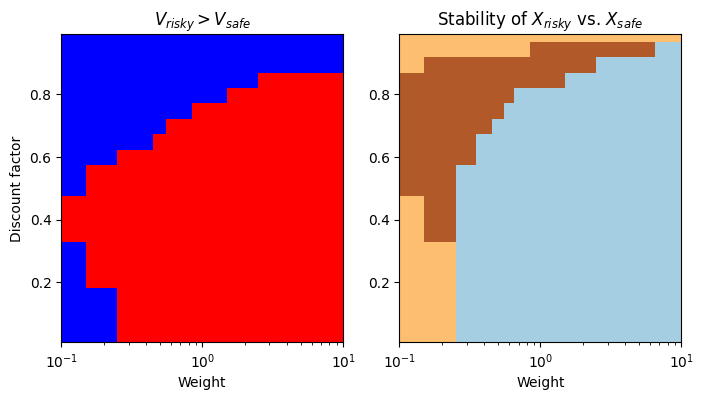

In [ ]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(8,4))
axes = [ax1, ax2]

ax1.pcolormesh(weights, discountfactors, 
               risky_optimal_data_container[:,:,0], cmap='bwr')
ax2.pcolormesh(weights, discountfactors, 
               indicator_stable[:,:,0], cmap='Paired')

for i, ax in enumerate(axes):
    ax.set_xlabel('Weight')
    ax.set_xscale('log')
    ax.set_xlim([0.1, 10])
    ax.set_ylim([0.01, 0.99])
    
ax1.set_ylabel('Discount factor')
ax1.set_title(r'$V_{risky} > V_{safe}$')
ax2.set_title('Stability of '+r'$X_{risky}$'+' vs. '+r'$X_{safe}$')

In [ ]:
aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                      learning_rates=0.1, discount_factors=0.6, 
                      Rmin=0, Rmax=1,
                      method="weights", wU=0.1, use_prefactor=True)

In [ ]:
Vv = aei.Visav(Xsafe)

<BarContainer object of 29 artists>

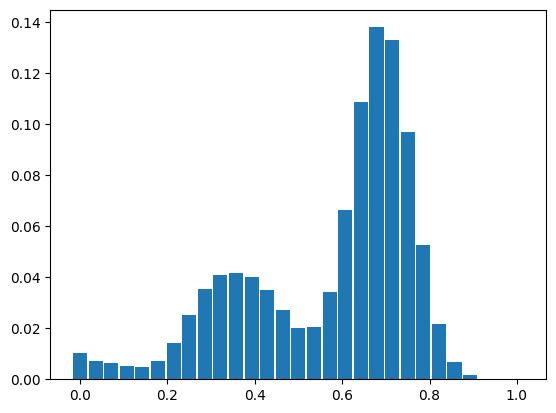

In [ ]:
plt.bar(aei.gridpoints, Vv[0,0,1,:], width=0.9*aei.gridwidth)

In [ ]:
gammas = [0.2, 0.4, 0.6, 0.8]
weights = [0.1, 0.2, 0.3, 0.4]

Text(0, 0.5, '$V^{0,0,v}$')

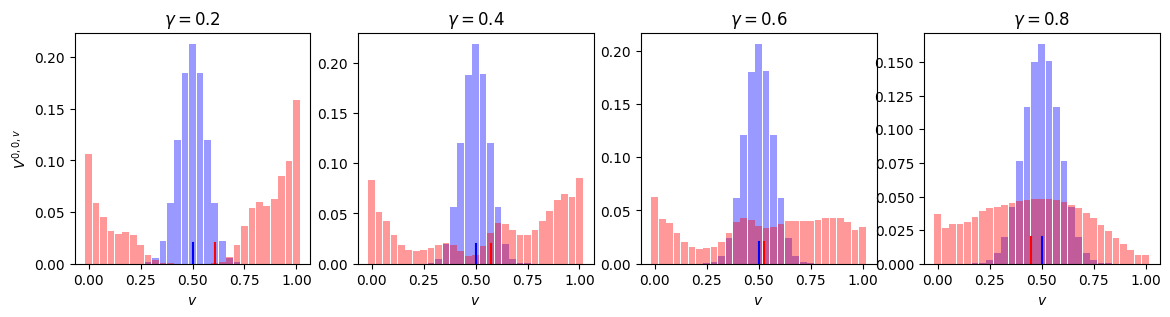

In [ ]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize = (14, 3))
axes = [ax1, ax2, ax3, ax4]

for i, ax in enumerate(axes):
    aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                          learning_rates=0.1, discount_factors=gammas[i], 
                          Rmin=0, Rmax=1,
                          method="weights", wU=0.1, use_prefactor=True)
    Vsafe = aei.Visv(Xsafe)
    Vrisk = aei.Visv(Xrisk)
    Vsm = np.dot(Vsafe[0,0,:], aei.gridpoints)
    Vrm = np.dot(Vrisk[0,0,:], aei.gridpoints)
    ax.bar(aei.gridpoints, Vsafe[0,0,:], width=0.9*aei.gridwidth,
          color="blue", alpha=0.4)
    ax.bar(aei.gridpoints, Vrisk[0,0,:], width=0.9*aei.gridwidth,
          color="red", alpha=0.4)
    ax.plot([Vsm, Vsm], [0, 0.02], color="blue")
    ax.plot([Vrm, Vrm], [0, 0.02], color="red")
    ax.set_title(r'$\gamma =$'+str(gammas[i]))
    ax.set_xlabel(r'$v$')
ax1.set_ylabel(r'$V^{0,0,v}$')